In [6]:
import pandas as pd

df = pd.read_csv("registration_fact.csv")

print(df.head())

     month        make fuel_type               body  registrations
0  2022-07  ALFA ROMEO    Petrol  Coupe/Convertible              0
1  2022-07  ALFA ROMEO    Petrol          Hatchback              0
2  2022-07  ALFA ROMEO    Petrol                MPV              0
3  2022-07  ALFA ROMEO    Petrol                SUV              0
4  2022-07  ALFA ROMEO    Petrol              Sedan              1


P4 minus P3:
body
SUV      11127
Sedan     1239
MPV        328
dtype: int64


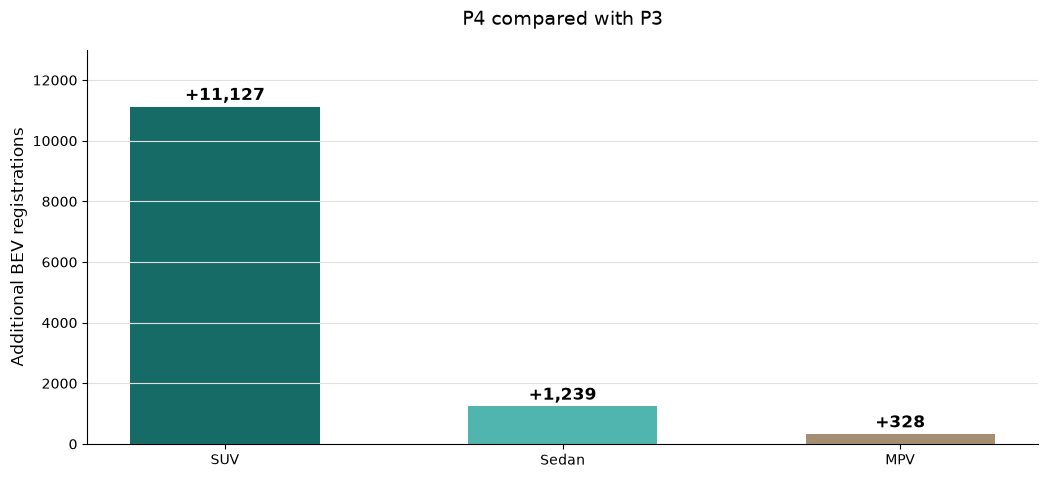

In [9]:
import matplotlib.pyplot as plt

segments = ["SUV", "Sedan", "MPV"]

df["month"] = pd.to_datetime(df["month"], format="%Y-%m")
df["registrations"] = pd.to_numeric(df["registrations"])

bev = df[
    (df["fuel_type"] == "Electric") &
    (df["body"].isin(segments))
].copy()

monthly = (
    bev.groupby(["month", "body"])["registrations"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=segments)
    .sort_index()
)

p3 = monthly.loc["2024-08":"2025-07"].sum()
p4 = monthly.loc["2025-08":"2026-07"].sum()
increase = p4 - p3

print("P4 minus P3:")
print(increase)

colors = {
    "SUV": "#176B66",
    "Sedan": "#4FB5AE",
    "MPV": "#A58F72"
}

fig, ax = plt.subplots(figsize=(10.58, 4.88))

bars = ax.bar(
    segments, increase[segments],
    color=[colors[x] for x in segments],
    width=0.56
)

ax.set_title("P4 compared with P3", fontsize=14, pad=18)
ax.set_ylabel("Additional BEV registrations", fontsize=12)
ax.set_ylim(0, 13000)
ax.set_yticks(range(0, 12001, 2000))
ax.grid(axis="y", color="#E1E1E1")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar, value in zip(bars, increase[segments]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 220,
        f"+{int(value):,}",
        ha="center", fontsize=12, fontweight="bold"
    )

plt.tight_layout()
plt.savefig("Q2_Figure_6_1_P4_vs_P3.png", dpi=300, bbox_inches="tight")
plt.show()

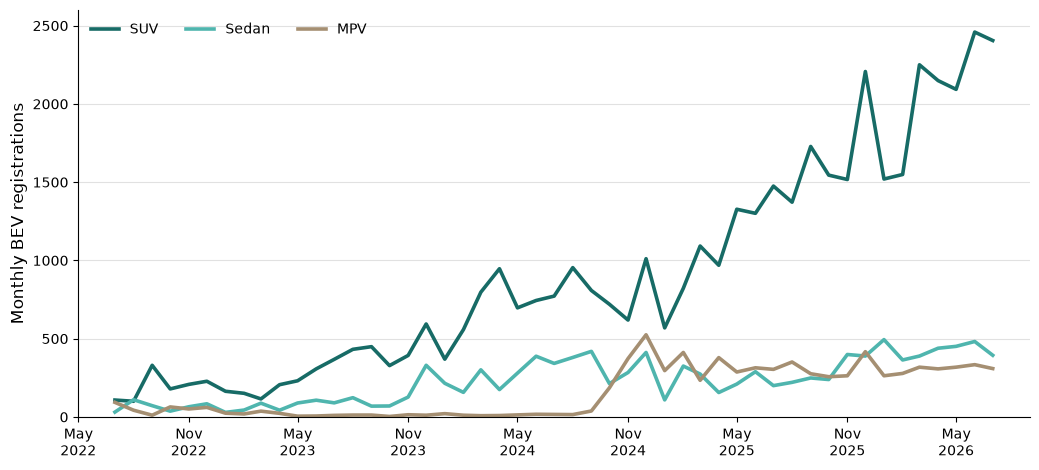

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10.5, 4.8))

for segment in segments:
    ax.plot(
        monthly.index,
        monthly[segment],
        label=segment,
        color=colors[segment],
        linewidth=2.6
    )

ax.set_ylabel("Monthly BEV registrations", fontsize=12)
ax.set_ylim(0, 2600)
ax.set_yticks(range(0, 2501, 500))
ax.set_xlim(pd.Timestamp("2022-05-01"), pd.Timestamp("2026-09-01"))

ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[5, 11]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

ax.legend(loc="upper left", ncol=3, frameon=False)
ax.grid(axis="y", color="#E1E1E1")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig("Q2_Figure_6_2_monthly_BEV_trend.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
import numpy as np
from pathlib import Path

periods = {
    "P1": ("2022-08", "2023-07"),
    "P2": ("2023-08", "2024-07"),
    "P3": ("2024-08", "2025-07"),
    "P4": ("2025-08", "2026-07")
}

def period_months(period):
    start, end = periods[period]
    return monthly.loc[start:end]

# P3 and P4 BEV market comparison
p3_market = period_months("P3").sum()
p4_market = period_months("P4").sum()

# All-fuel registrations: used only for BEV penetration
all_fuel = df[df["body"].isin(segments)].copy()

p4_all_fuel = (
    all_fuel[
        (all_fuel["month"] >= "2025-08") &
        (all_fuel["month"] <= "2026-07")
    ]
    .groupby("body")["registrations"]
    .sum()
    .reindex(segments)
)

# Largest non-BYD competitor in each segment during P4
competitors_p4 = (
    bev[
        (bev["month"] >= "2025-08") &
        (bev["month"] <= "2026-07") &
        (bev["make"] != "BYD")
    ]
    .groupby(["body", "make"])["registrations"]
    .sum()
    .reset_index(name="competitor_units")
    .sort_values(["body", "competitor_units"], ascending=[True, False])
    .drop_duplicates("body")
    .set_index("body")
    .reindex(segments)
)

table_6_1 = pd.DataFrame({
    "P3 market": p3_market,
    "P4 market": p4_market,
    "Growth increase": p4_market - p3_market,
    "Growth (%)": (p4_market / p3_market - 1) * 100,
    "BEV penetration (%)": p4_market / p4_all_fuel * 100,
    "Largest non-BYD competitor": competitors_p4["make"],
    "Largest competitor share (%)":
        competitors_p4["competitor_units"] / p4_market * 100
})

table_6_1.index.name = "Segment"
table_6_1 = table_6_1.round(1)

print("Table 6.1: Latest market comparison")
display(table_6_1)

table_6_1.to_csv("Q2_Table_6_1_market_comparison.csv")

# CV = standard deviation / mean for each segment and period
cv_table = pd.DataFrame({
    period: period_months(period).std(ddof=1) /
            period_months(period).mean() * 100
    for period in periods
}).T

cv_table.index.name = "Period"
cv_table = cv_table.round(1)

print("CV stability results (%)")
display(cv_table)

cv_table.to_csv("Q2_CV_stability_results.csv")

Table 6.1: Latest market comparison


,P3 market,P4 market,Growth increase,Growth (%),BEV penetration (%),Largest non-BYD competitor,Largest competitor share (%)
Segment,,,,,,,
SUV,11667,22794,11127,95.4,68.2,TESLA,18.2
Sedan,3271,4510,1239,37.9,50.3,TESLA,20.3
MPV,3363,3691,328,9.8,35.6,MAXUS,12.6


CV stability results (%)


body,SUV,Sedan,MPV
Period,,,
P1,38.8,38.7,71.8
P2,33.9,51.5,37.7
P3,29.5,36.5,52.5
P4,20.9,24.7,14.9


In [13]:
from scipy.stats import ttest_rel, t

test_rows = []

transitions = [
    ("P1", "P2"),
    ("P2", "P3"),
    ("P3", "P4")
]

for segment in segments:
    for earlier, later in transitions:

        earlier_values = period_months(earlier)[segment].reset_index(drop=True)
        later_values = period_months(later)[segment].reset_index(drop=True)

        difference = later_values - earlier_values

        t_stat, p_value = ttest_rel(later_values, earlier_values)

        n = len(difference)
        dfree = n - 1
        standard_error = difference.std(ddof=1) / np.sqrt(n)
        critical_value = t.ppf(0.975, dfree)

        ci_lower = difference.mean() - critical_value * standard_error
        ci_upper = difference.mean() + critical_value * standard_error

        test_rows.append({
            "Segment": segment,
            "Transition": f"{earlier} to {later}",
            "Earlier monthly mean": earlier_values.mean(),
            "Later monthly mean": later_values.mean(),
            "Mean change": difference.mean(),
            "95% CI lower": ci_lower,
            "95% CI upper": ci_upper,
            "t statistic": t_stat,
            "p value": p_value,
            "Positive matched months": int((difference > 0).sum()),
            "Matched months": n,
            "Significant at 5%": "Yes" if p_value < 0.05 else "No"
        })

table_6_2 = pd.DataFrame(test_rows).round(4)

print("Table 6.2: Paired t-tests")
display(table_6_2)

table_6_2.to_csv("Q2_Table_6_2_paired_ttests.csv", index=False)

Table 6.2: Paired t-tests


,Segment,Transition,Earlier monthly mean,Later monthly mean,Mean change,95% CI lower,95% CI upper,t statistic,p value,Positive matched months,Matched months,Significant at 5%
0,SUV,P1 to P2,215.5833,590.0000,374.4167,249.4199,499.4134,6.5929,0.0000,12,12,Yes
1,SUV,P2 to P3,590.0000,972.2500,382.2500,257.3350,507.1650,6.7352,0.0000,12,12,Yes
2,SUV,P3 to P4,972.2500,1899.5000,927.2500,781.3572,1073.1428,13.9888,0.0000,12,12,Yes
3,Sedan,P1 to P2,71.5000,214.7500,143.2500,80.1523,206.3477,4.9969,0.0004,11,12,Yes
4,Sedan,P2 to P3,214.7500,272.5833,57.8333,-42.7460,158.4127,1.2656,0.2318,6,12,No
5,Sedan,P3 to P4,272.5833,375.8333,103.2500,-4.5605,211.0605,2.1079,0.0588,9,12,No
6,MPV,P1 to P2,29.5000,12.2500,-17.2500,-32.4703,-2.0297,-2.4945,0.0298,4,12,Yes
7,MPV,P2 to P3,12.2500,280.2500,268.0000,174.9362,361.0638,6.3383,0.0001,12,12,Yes
8,MPV,P3 to P4,280.2500,307.5833,27.3333,-62.9393,117.6060,0.6664,0.5189,7,12,No
